# checkbox detector (YOLO)

Two datasets, both CC BY 4.0:

- `original`: [cogniquest-idc1w/checkboxes-xtv3p v5](https://universe.roboflow.com/cogniquest-idc1w/checkboxes-xtv3p/dataset/5) (2421 train, 206 validation, 206 test scanned pages, stretched to 1280x1280). Its weights are in `models/checkbox_yolo.pt`, which is what `services/yolo_detection.py` loads.
- `cleaned`: [tomas-agata/checkboxes-xtv3p-et5rc v2](https://universe.roboflow.com/tomas-agata/checkboxes-xtv3p-et5rc/dataset/2), my fork of the same dataset with the pages that threw the results off removed (1259 train, 105 validation, 109 test, kept at their native resolution). Its weights go to `models/checkbox_yolo_cleaned.pt`, so the served model only changes once I copy it over.

`TRAIN_ON` picks which one the notebook trains. Both are trained with the same settings, and then each model is scored on both test splits and on the repo benchmark.

The exports have overlapping classes (6 in `original`, `checked`/`unchecked` in `cleaned`). I merge them into a single `checkbox` class: the detector only has to find boxes, deciding checked/unchecked stays with the CNN classifier (see `cnn.ipynb`).

The model is trained on the raw scans, not on the binarized output of the preprocessing service, so at inference it expects the grayscale page (as 3 channels).

In [1]:
import os

# Set the ROCm override version for your graphics card
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "10.3.0"

# Verify that it was set correctly
print("HSA_OVERRIDE_GFX_VERSION is set to:", os.environ.get("HSA_OVERRIDE_GFX_VERSION"))

HSA_OVERRIDE_GFX_VERSION is set to: 10.3.0


In [ ]:
import random
import shutil
import zipfile
from pathlib import Path

import torch
import yaml
from PIL import Image, ImageDraw
from ultralytics import YOLO

from services.detection import get_detection_service
from services.preprocessing import get_preprocessing_service
from services.yolo_detection import DetectionService
from tests.evaluation import IOU_THRESHOLD, DetectionResult, load_all_samples, match

random.seed(0)

ROOT = Path.cwd()
DATASETS = ["original", "cleaned"]
ZIP_PATHS = {
    "original": ROOT / "checkboxes.v5i.yolov8.zip",
    "cleaned": ROOT / "checkboxes.v2i.yolov8.zip",
}
DATASET_DIRS = {
    "original": ROOT / "datasets" / "checkboxes",
    "cleaned": ROOT / "datasets" / "checkboxes_cleaned",
}
DATA_YAMLS = {name: DATASET_DIRS[name] / "data.yaml" for name in DATASETS}
YOLO_MODEL_PATHS = {
    "original": ROOT / "models" / "checkbox_yolo.pt",
    "cleaned": ROOT / "models" / "checkbox_yolo_cleaned.pt",
}
TRAIN_ON = "cleaned"  # the original model is already trained, its weights are in models/

BASE_WEIGHTS = "yolo26s.pt"  # small model: nano misses tiny boxes, medium is slow to train
IMGSZ = 1280  # checkboxes are only a few dozen pixels, downscaling the 1280px pages would lose them
DEVICE = 0 if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    print("warning: no CUDA device found, training on CPU will take many hours")

## Data

In [3]:
SPLITS = ["train", "valid", "test"]

for name in DATASETS:
    dataset_dir = DATASET_DIRS[name]
    if not dataset_dir.exists():
        with zipfile.ZipFile(ZIP_PATHS[name]) as z:
            z.extractall(dataset_dir)

    # Merge every class into 0 = checkbox. Only the class id is rewritten, the coordinates stay as they are.
    for label_file in dataset_dir.glob("*/labels/*.txt"):
        lines = [line.split(maxsplit=1) for line in label_file.read_text().splitlines() if line.strip()]
        label_file.write_text("".join(f"0 {coords}\n" for _, coords in lines))

    # Ultralytics caches parsed labels next to the label folders, a stale cache would keep the old class ids.
    for cache in dataset_dir.glob("*/labels*.cache"):
        cache.unlink()

    # The exported data.yaml uses paths relative to a folder that doesn't exist here, so write a fresh one.
    # The test split is a list of the held-out pages, written in the next cells.
    DATA_YAMLS[name].write_text(yaml.safe_dump({
        "path": str(dataset_dir),
        "train": "train/images",
        "val": "valid/images",
        "test": "test_heldout.txt",
        "names": {0: "checkbox"},
    }))
    print(f"{name}:\n{DATA_YAMLS[name].read_text()}")

original:
names:
  0: checkbox
path: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes
test: test_heldout.txt
train: train/images
val: valid/images

cleaned:
names:
  0: checkbox
path: /home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes_cleaned
test: test_heldout.txt
train: train/images
val: valid/images



In [4]:
def read_boxes(label_file: Path) -> list[tuple[float, float, float, float]]:
    """YOLO label file -> normalized (cx, cy, w, h) boxes."""
    return [tuple(map(float, line.split()[1:5])) for line in label_file.read_text().splitlines()]


def box_sides(split_dir: Path) -> list[float]:
    """Shorter side of every labelled box in pixels, once YOLO has scaled the page's long side to IMGSZ."""
    sides = []
    for image_path in (split_dir / "images").iterdir():
        width, height = Image.open(image_path).size  # only reads the header
        scale = IMGSZ / max(width, height)
        sides += [min(w * width, h * height) * scale
                  for _, _, w, h in read_boxes(split_dir / "labels" / f"{image_path.stem}.txt")]
    return sorted(sides)


for name in DATASETS:
    for split in SPLITS:
        sides = box_sides(DATASET_DIRS[name] / split)
        n_images = len(list((DATASET_DIRS[name] / split / "images").iterdir()))
        print(f"{name:8} {split:5}: {n_images:4} images, {len(sides):5} boxes, median box side {sides[len(sides) // 2]:.0f}px")

original train: 2420 images, 31203 boxes, median box side 18px
original valid:  205 images,  2619 boxes, median box side 20px
original test :  205 images,  2313 boxes, median box side 18px
cleaned  train: 1259 images, 23500 boxes, median box side 16px
cleaned  valid:  105 images,  1689 boxes, median box side 17px
cleaned  test :  109 images,  1699 boxes, median box side 16px


The cleaned set is a fork of the original, and Roboflow re-split a few pages along the way: about a dozen pages in each test split are in the other dataset's train or validation split. Scoring a model on pages it trained on (or picked its best epoch with) would flatter it, so each test split only keeps the pages that neither model has seen.

In [5]:
def page_id(image_path: Path) -> str:
    """Roboflow renames exported pages to <source name>.rf.<hash>, the source name identifies a page across exports."""
    return image_path.name.split(".rf.")[0]


for name in DATASETS:
    seen_by_others = {page_id(p) for other in DATASETS if other != name
                      for split in ["train", "valid"] for p in (DATASET_DIRS[other] / split / "images").iterdir()}
    test_images = sorted((DATASET_DIRS[name] / "test" / "images").iterdir())
    heldout = [p for p in test_images if page_id(p) not in seen_by_others]
    (DATASET_DIRS[name] / "test_heldout.txt").write_text("".join(f"{p}\n" for p in heldout))
    print(f"{name:8} test: {len(heldout)} of {len(test_images)} pages held out from both models")

original test: 190 of 205 pages held out from both models
cleaned  test: 95 of 109 pages held out from both models


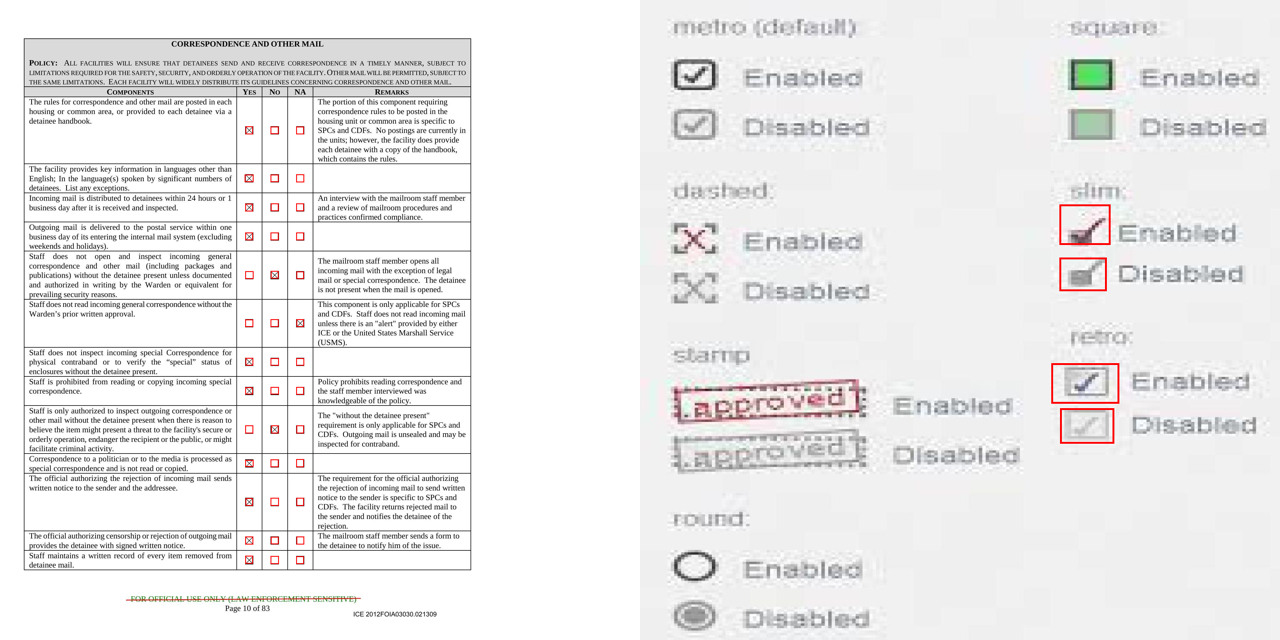

In [6]:
# Two random training pages with their labelled boxes.
train_dir = DATASET_DIRS[TRAIN_ON] / "train"
grid = Image.new("RGB", (1280, 640), "white")
for i, image_path in enumerate(random.sample(sorted((train_dir / "images").iterdir()), 2)):
    img = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(img)
    for cx, cy, w, h in read_boxes(train_dir / "labels" / f"{image_path.stem}.txt"):
        draw.rectangle([(cx - w / 2) * img.width, (cy - h / 2) * img.height,
                        (cx + w / 2) * img.width, (cy + h / 2) * img.height], outline="red", width=3)
    img.thumbnail((640, 640))  # the cleaned pages aren't square, keep their aspect ratio
    grid.paste(img, (i * 640, 0))
grid

## Train

In [7]:
# Same settings for both datasets, so the only difference between the two models is the data.
model = YOLO(BASE_WEIGHTS)
results = model.train(
    data=DATA_YAMLS[TRAIN_ON],
    imgsz=IMGSZ,
    epochs=100,
    patience=20,  # stop early once validation mAP stops improving
    batch=4,
    device=DEVICE,
    seed=0,
    project=ROOT / "runs",
    name=f"checkbox_yolo_{TRAIN_ON}",
    exist_ok=True,
)

Ultralytics 8.4.197 🚀 Python-3.13.5 torch-2.14.1+rocm7.2 CUDA:0 (AMD Radeon RX 6700 XT, 12272MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/tomas/Interviews/HomeVisionTHSubmission/datasets/checkboxes_cleaned/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0

KeyboardInterrupt: 

In [ ]:
YOLO_MODEL_PATHS[TRAIN_ON].parent.mkdir(exist_ok=True)
shutil.copy(Path(results.save_dir) / "weights" / "best.pt", YOLO_MODEL_PATHS[TRAIN_ON])
print(f"saved best model to {YOLO_MODEL_PATHS[TRAIN_ON]}")

## Test

Both models are scored on both held-out test splits, with the saved weights loaded from `models/`, so the files themselves get exercised as well. The cleaned labels are the stricter reference, but a model that only does well on its own test split would be a red flag.

In [ ]:
detection_services = {name: DetectionService(YOLO_MODEL_PATHS[name]) for name in DATASETS}
rows = []
for model_name, service in detection_services.items():
    for data_name in DATASETS:
        metrics = service.model.val(data=DATA_YAMLS[data_name], split="test", imgsz=IMGSZ, device=DEVICE,
                                    plots=False, verbose=False)
        rows.append((model_name, data_name, metrics.box))

print(f"{'model':8} {'test set':8} {'mAP50':>6} {'mAP50-95':>8} {'prec':>6} {'recall':>6}")
for model_name, data_name, box in rows:
    print(f"{model_name:8} {data_name:8} {box.map50:6.3f} {box.map:8.3f} {box.mp:6.3f} {box.mr:6.3f}")

## Repo benchmark

The same pages and matching as the pytest detection report (`data/<dataset>`, IoU >= 0.5), with both YOLO models and the OpenCV contour detector side by side. None of these pages are in either training set, so this is the comparison that decides which weights get served.

The YOLO models run through `DetectionService`, the same code the API uses, so the benchmark includes its preprocessing: pages larger than `IMGSZ` are shrunk with `INTER_AREA` before prediction. Ultralytics' own resize (`INTER_LINEAR`) broke the thin borders on the full-resolution scans: on `fullres/canvas1.png` recall went from 0.75 to 0.98 with the change.

In [ ]:
def opencv_find_checkboxes(gray) -> list[list[int]]:
    return get_detection_service().find_checkboxes(get_preprocessing_service().cleanup_image(gray))


def fmt(value):
    return "-" if value is None else f"{value:.2f}"


samples = load_all_samples()
detectors = {f"yolo_{name}": service.find_checkboxes for name, service in detection_services.items()}
detectors["opencv"] = opencv_find_checkboxes
totals = {}
print(f"IoU >= {IOU_THRESHOLD}")
print(f"{'sample':24} {'detector':13} {'GT':>5} {'pred':>5} {'TP':>5} {'prec':>6} {'recall':>6} {'F1':>6}")
for sample in samples:
    gray = sample.load_gray()
    truths = [a.bbox for a in sample.annotations]
    for name, find in detectors.items():
        preds = find(gray)
        r = DetectionResult(match(preds, truths), len(preds), len(truths))
        key = (sample.dataset, name)
        totals[key] = totals[key] + r if key in totals else r
        print(f"{sample.id:24} {name:13} {r.n_gt:5} {r.n_pred:5} {r.tp:5} {fmt(r.precision):>6} {fmt(r.recall):>6} {fmt(r.f1):>6}")
print()
for (dataset, name), r in sorted(totals.items()):
    print(f"{dataset + ' (total)':24} {name:13} {r.n_gt:5} {r.n_pred:5} {r.tp:5} {fmt(r.precision):>6} {fmt(r.recall):>6} {fmt(r.f1):>6}")

In [ ]:
# Boxes from the model trained on TRAIN_ON (red) vs. labelled boxes (green) on one page, to eyeball misses and false positives.
sample = samples[0]
gray = sample.load_gray()
page = Image.fromarray(gray).convert("RGB")
draw = ImageDraw.Draw(page)
for x, y, w, h in (a.bbox for a in sample.annotations):
    draw.rectangle([x, y, x + w, y + h], outline="green", width=5)
for x, y, w, h in detection_services[TRAIN_ON].find_checkboxes(gray):
    draw.rectangle([x, y, x + w, y + h], outline="red", width=2)
print(sample.id)
page.resize((1000, round(page.height * 1000 / page.width)))